# Practice 13 — Fine-tuning on a New Class

**Goal:** teach a pretrained detector a class it has never seen — `crack`, on concrete and asphalt surfaces.

| Question | Answer this notebook gives |
|:---|:---|
| What is fine-tuning for? | teaching a class the weights have never seen |
| How much data does it take? | a couple of hundred images, since the pretrained backbone is reused |
| What changes for masks instead of boxes? | the weights file, and nothing else in the call |

- A pretrained detector knows 80 classes → yours is usually not one of them

---
## Step 0. Setup

- `ultralytics` → the model, the training loop and the metrics
- `YOLO_VERBOSE` set before the import → no progress bar for every batch

In [1]:
import os
import subprocess
import sys

os.environ['YOLO_VERBOSE'] = 'False'

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.194


In [2]:
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# the weights and the dataset are saved under these two folders; training runs go to runs/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


In [3]:
crack_dir = DATA / 'crack_full'

if not crack_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip',
        BUILD / 'crack-seg.zip')
    # this archive has no top level folder inside, so the destination folder is named here
    with zipfile.ZipFile(BUILD / 'crack-seg.zip') as archive:
        archive.extractall(crack_dir)

for split in ['train', 'val', 'test']:
    images = sorted((crack_dir / 'images' / split).glob('*.jpg'))
    print(f'{split:5s} : {len(images)} images')

train : 3717 images
val   : 200 images
test  : 112 images


---
## Step 1. What the Pretrained Models Do Here

- `yolo11n` (boxes) and `yolo11n-seg` (masks, one pixel region per object) → the COCO weights, untouched
- `conf=0.25` → detections below 25% confidence are dropped
- `result.plot()` returns BGR → the channels are reversed for matplotlib

In [4]:
model_pretrained = YOLO(str(BUILD / 'yolo11n.pt'))
model_pretrained_seg = YOLO(str(BUILD / 'yolo11n-seg.pt'))

crack_in_coco = 'crack' in model_pretrained.names.values()
print(f"'crack' among the 80 class names : {crack_in_coco}")
print()

crack_images = sorted((crack_dir / 'images' / 'test').glob('*.jpg'))[:4]
for image_path in crack_images:
    detection_result = model_pretrained.predict(image_path, conf=0.25, verbose=False)[0]
    segmentation_result = model_pretrained_seg.predict(image_path, conf=0.25, verbose=False)[0]
    print(f'{image_path.name[:12]} : detection {len(detection_result.boxes)} objects, '
          f'segmentation {len(segmentation_result.boxes)} objects')

'crack' among the 80 class names : False



1616.rf.c868 : detection 0 objects, segmentation 0 objects
1675.rf.e3aa : detection 0 objects, segmentation 0 objects
1686.rf.809f : detection 0 objects, segmentation 0 objects
1706.rf.011d : detection 0 objects, segmentation 0 objects


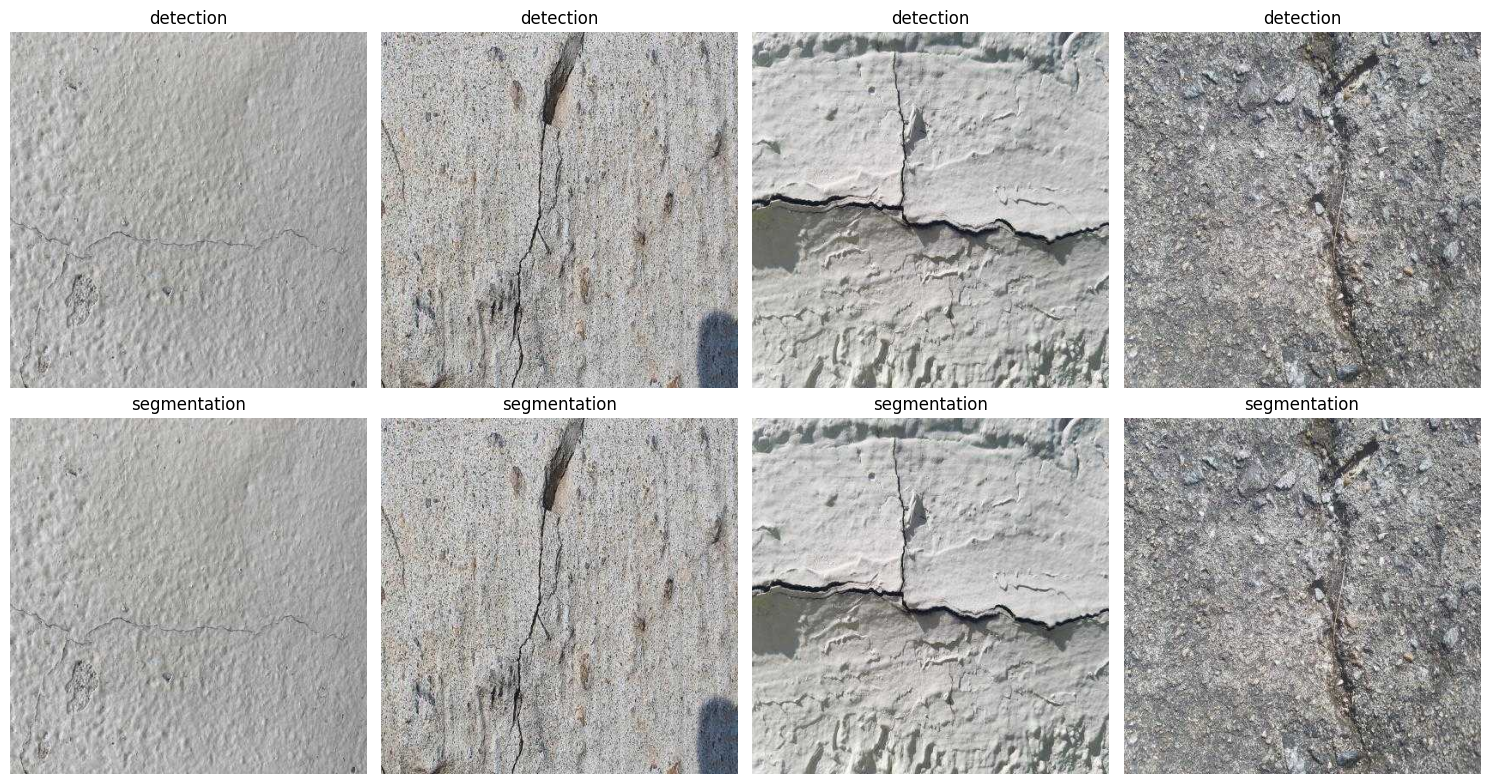

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for column, image_path in enumerate(crack_images):
    detection_result = model_pretrained.predict(image_path, conf=0.25, verbose=False)[0]
    segmentation_result = model_pretrained_seg.predict(image_path, conf=0.25, verbose=False)[0]

    axes[0, column].imshow(detection_result.plot()[:, :, ::-1])
    axes[0, column].set_title('detection')
    axes[0, column].axis('off')

    axes[1, column].imshow(segmentation_result.plot()[:, :, ::-1])
    axes[1, column].set_title('segmentation')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()

- Nothing is drawn on any panel, yet the weights are not broken
- The output layer has 80 slots fixed at training time → none of them means `crack`

---
## Step 2. The Label Format

- `images/` and `labels/` mirror each other → one label file of the same name per image

| Label | One line | Length |
|:---|:---|:---|
| Segmentation | `class x1 y1 x2 y2 ... xn yn`, an outline | varies |
| Detection | `class cx cy w h` | fixed |

- One line per object, coordinates divided by the image size; the next cell reads one file's first line

In [6]:
image_path = crack_images[0]
label_path = crack_dir / 'labels' / 'test' / (image_path.stem + '.txt')
label_line = label_path.read_text().strip().split('\n')[0]

numbers = label_line.split()
n_coordinates = len(numbers) - 1
n_points = n_coordinates // 2
print(f'class          : {numbers[0]}')
print(f'coordinates    : {n_coordinates}')
print(f'outline points : {n_points}')
print()
print('first 8 coordinates')
print(' '.join(numbers[1:9]))

class          : 0
coordinates    : 174
outline points : 87

first 8 coordinates
0.03686995913461539 0.9808467740384615 0.03245967788461539 0.9595654110576923 0.030569555288461538 0.9517249110576922 0.03497983894230769 0.9438844086538462


- 87 points trace one crack; a detection model reads the same line as the outline's bounding box → one dataset trains both kinds of model

---
## Step 3. Pointing YOLO at the Data

- `crack.yaml` → where the folders are, what the class indices mean
- `test` → used neither for training nor for picking the best epoch, so it is the split reported below

In [7]:
crack_yaml_path = (DATA / 'crack.yaml').resolve()

# the three folders are written relative to the folder this file sits in
with open(crack_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: crack_full/images/train\n')
    yaml_file.write('val: crack_full/images/val\n')
    yaml_file.write('test: crack_full/images/test\n')
    yaml_file.write('names:\n')
    yaml_file.write('  0: crack\n')

print(crack_yaml_path.read_text().strip())

train: crack_full/images/train
val: crack_full/images/val
test: crack_full/images/test
names:
  0: crack


- `val(split='test')` → box mAP@50 on the test split; a predicted box counts when its IoU with a label is at least 0.5
- `imgsz=320` → images resized to 320 px for speed, the same for scoring and training
- `name` → the run folder, `runs/detect/crack_pretrained_test`; every `val()` and `train()` below names its own
- This is run A of the comparison in Step 5

In [8]:
metrics_pretrained = model_pretrained.val(data=str(crack_yaml_path), split='test', imgsz=320, name='crack_pretrained_test')
map50_test_pretrained = metrics_pretrained.box.map50

print(f'pretrained box mAP@50 : {map50_test_pretrained:.5f}')

pretrained box mAP@50 : 0.01057


- 0.011, not exactly zero → the dataset has one class, index 0, and COCO's index 0 is `person`; a `person` box that happens to overlap a crack counts — the floor to beat

- `val()` saves pictures in its run folder → the labels it read, outlines turned into boxes, next to the pretrained predictions

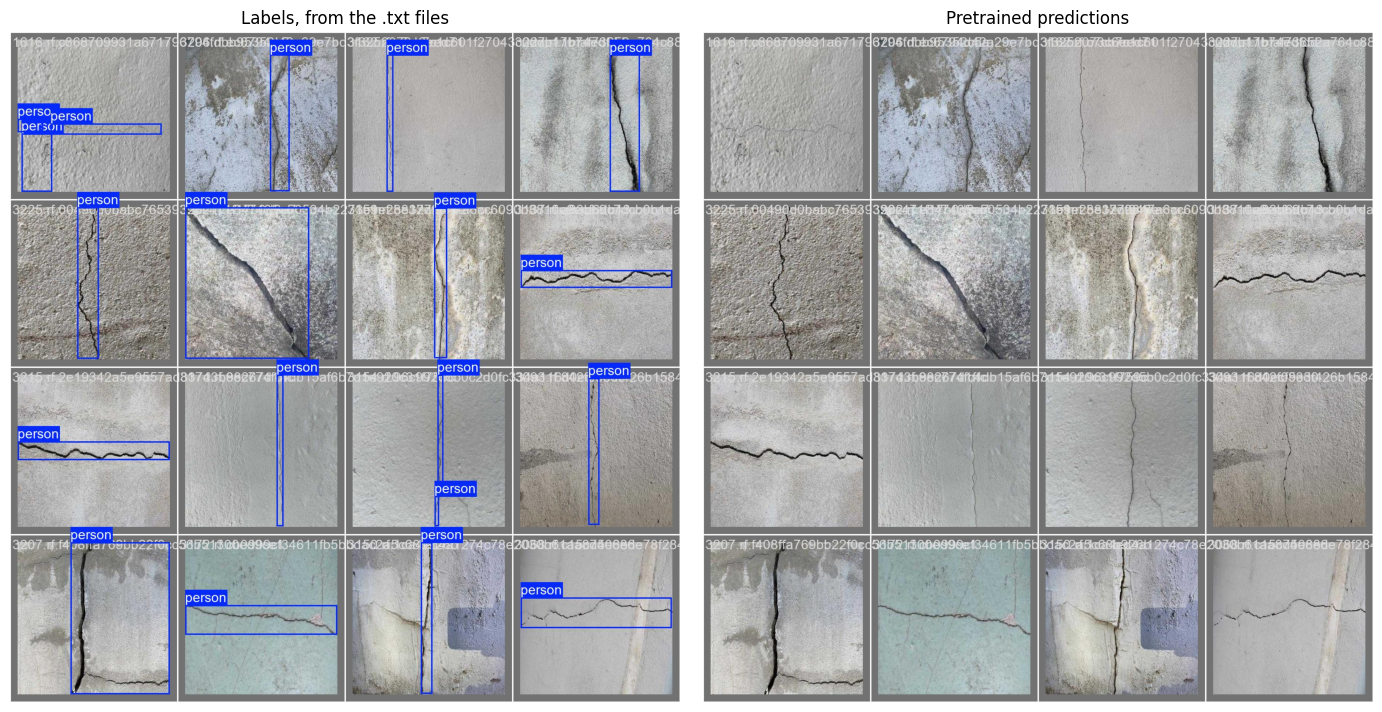

In [9]:
val_dir = Path(metrics_pretrained.save_dir)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(Image.open(val_dir / 'val_batch0_labels.jpg'))
axes[0].set_title('Labels, from the .txt files')

axes[1].imshow(Image.open(val_dir / 'val_batch0_pred.jpg'))
axes[1].set_title('Pretrained predictions')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Left: every label box is captioned `person` → the pretrained model's name for class 0; right: none of its predictions is confident enough to be drawn

---
## Step 4. Fine-tuning a Detector

| Argument | Effect |
|:---|:---|
| `fraction=0.05` | 5% of the training images, about 186 |
| `optimizer='SGD'`, `lr0=0.01` | optimizer and initial learning rate |
| `patience=0` | early stopping off |
| `amp=False` | mixed precision off (its check downloads another model) |
| `name` | run folder `runs/detect/crack_detect` |

- `train()` rebuilds the output layer for the one class; every other layer keeps training from the COCO weights
- Each epoch scores `val` and keeps the best weights; `val(split='test')` then scores them → run B

In [10]:
epochs = 20
fraction = 0.05

# workers=0 → the data loading stays in this process, which a notebook on Windows needs
model_finetuned = YOLO(str(BUILD / 'yolo11n.pt'))
model_finetuned.train(data=str(crack_yaml_path), epochs=epochs, fraction=fraction,
                      imgsz=320, batch=16, optimizer='SGD', lr0=0.01,
                      seed=42, amp=False, workers=0, patience=0, name='crack_detect')

metrics_finetuned = model_finetuned.val(data=str(crack_yaml_path), split='test', imgsz=320, name='crack_detect_test')
map50_test_finetuned = metrics_finetuned.box.map50

print(f'fine-tuned box mAP@50 : {map50_test_finetuned:.5f}')

fine-tuned box mAP@50 : 0.53122


- 0.011 → 0.53 on the test split, from about 186 images and 20 epochs
- `seed=42` repeats the run on the same machine; another GPU or library version shifts it a little

- Every epoch is logged to `results.csv` in the run folder, `trainer.save_dir` → `(B)` marks the box scores; a segmentation run also logs `(M)` for masks

   epoch  train/box_loss  val/box_loss  metrics/mAP50(B)
0      1         2.07287       1.96271           0.07260
1      2         1.67252       1.32206           0.50838
2      3         1.59382       1.65342           0.18175
3      4         1.54846       2.04153           0.19650
4      5         1.59228       2.04691           0.31985


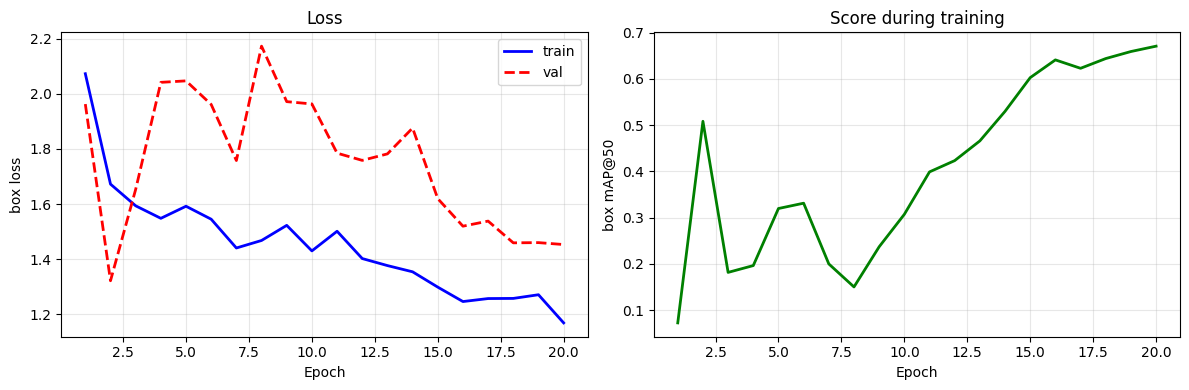

In [11]:
history_finetuned = pd.read_csv(Path(model_finetuned.trainer.save_dir) / 'results.csv')
print(history_finetuned[['epoch', 'train/box_loss', 'val/box_loss', 'metrics/mAP50(B)']].head())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_finetuned['epoch'], history_finetuned['train/box_loss'], 'b-',
             linewidth=2, label='train')
axes[0].plot(history_finetuned['epoch'], history_finetuned['val/box_loss'], 'r--',
             linewidth=2, label='val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('box loss')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_finetuned['epoch'], history_finetuned['metrics/mAP50(B)'], 'g-', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('box mAP@50')
axes[1].set_title('Score during training')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Training loss falls through the run; validation loss swings between 1.3 and 2.2 in the first ten epochs, then settles near 1.45
- The curve scores the `val` split after every epoch, the 0.53 above the `test` split → noisy (0.51 at epoch 2, 0.15 at epoch 8, 0.67 at epoch 20), trend up

- The fine-tuned detector on the four test images of Step 1

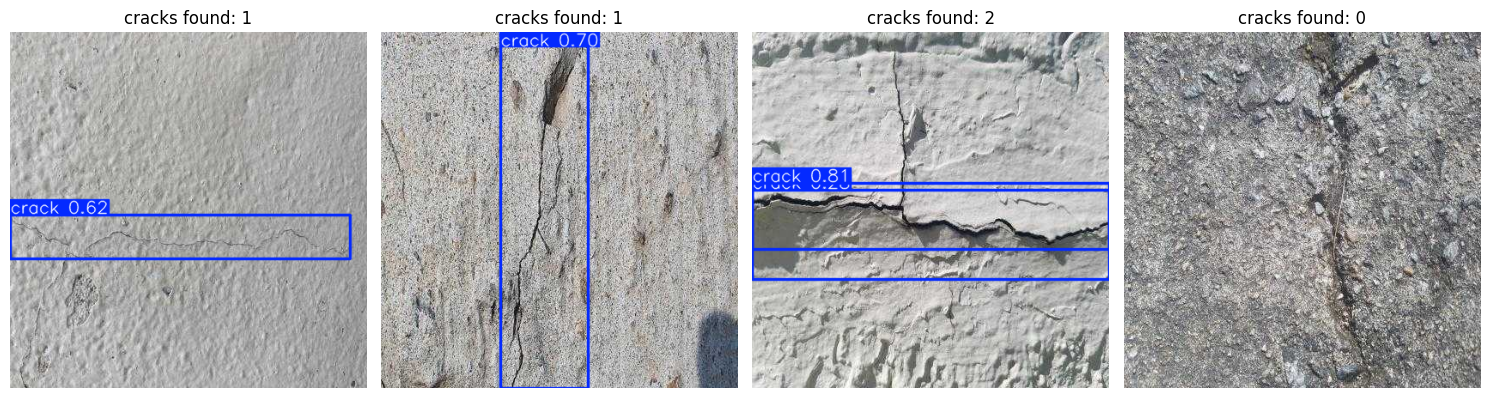

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for panel_axis, image_path in zip(axes, crack_images):
    result = model_finetuned.predict(image_path, conf=0.25, verbose=False)[0]
    panel_axis.imshow(result.plot()[:, :, ::-1])
    panel_axis.set_title(f'cracks found: {len(result.boxes)}')
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- A box that spans the frame is not a mistake → the crack runs across it; the fourth image gets nothing at `conf=0.25`

---
## Step 5. Why the Pretrained Weights Matter

| Item | A: pretrained | B: fine-tuned | C: from scratch |
|:---|:---|:---|:---|
| **initial weights** | **COCO** | **COCO** | **random** |
| **training** | **none** | **20 epochs** | **20 epochs** |
| `fraction`, `batch`, `lr0`, `seed` | · | same | same |
| data, `imgsz`, test split | same | same | same |

- A vs B → the training; B vs C → the starting weights

In [13]:
# the architecture file ships inside the ultralytics package; building from it loads no pretrained weights
model_scratch = YOLO('yolo11n.yaml')
model_scratch.train(data=str(crack_yaml_path), epochs=epochs, fraction=fraction,
                    imgsz=320, batch=16, optimizer='SGD', lr0=0.01,
                    seed=42, amp=False, workers=0, patience=0, name='crack_scratch')

metrics_scratch = model_scratch.val(data=str(crack_yaml_path), split='test', imgsz=320, name='crack_scratch_test')
map50_test_scratch = metrics_scratch.box.map50

print(f'from-scratch box mAP@50 : {map50_test_scratch:.5f}')

from-scratch box mAP@50 : 0.00279


In [14]:
print('                  box mAP@50')
print(f'A pretrained     {map50_test_pretrained:11.5f}')
print(f'B fine-tuned     {map50_test_finetuned:11.5f}')
print(f'C from scratch   {map50_test_scratch:11.5f}')

                  box mAP@50
A pretrained         0.01057
B fine-tuned         0.53122
C from scratch       0.00279


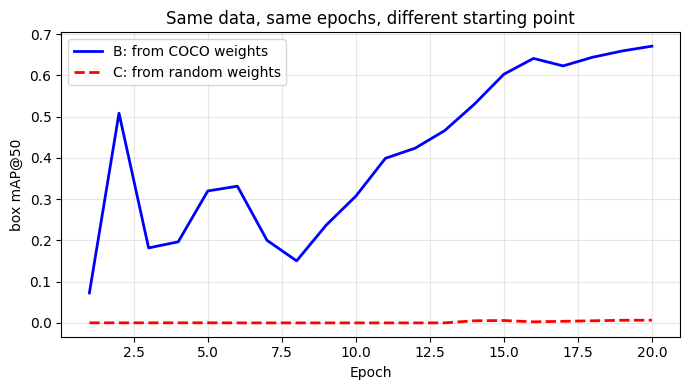

In [15]:
history_scratch = pd.read_csv(Path(model_scratch.trainer.save_dir) / 'results.csv')

plt.figure(figsize=(7, 4))
plt.plot(history_finetuned['epoch'], history_finetuned['metrics/mAP50(B)'], 'b-',
         linewidth=2, label='B: from COCO weights')
plt.plot(history_scratch['epoch'], history_scratch['metrics/mAP50(B)'], 'r--',
         linewidth=2, label='C: from random weights')
plt.xlabel('Epoch')
plt.ylabel('box mAP@50')
plt.title('Same data, same epochs, different starting point')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- C never leaves the bottom, 0.003 on the test split → same images, epochs and learning rate, but no backbone that already knows edges and textures
- A couple of hundred images can name a new class, not teach vision from nothing

---
## Step 6. The Same Training, With Masks

- `yolo11n-seg.pt` replaces `yolo11n.pt` → nothing else in the call changes
- Same dataset → its labels were outlines all along
- Validation now reports two scores → one for boxes, one for masks

In [16]:
model_seg = YOLO(str(BUILD / 'yolo11n-seg.pt'))
model_seg.train(data=str(crack_yaml_path), epochs=epochs, fraction=fraction,
                imgsz=320, batch=16, optimizer='SGD', lr0=0.01,
                seed=42, amp=False, workers=0, patience=0, name='crack_segment')

metrics_seg = model_seg.val(data=str(crack_yaml_path), split='test', imgsz=320, name='crack_segment_test')
map50_test_seg = metrics_seg.box.map50
mask_map50_test_seg = metrics_seg.seg.map50

print(f'box  mAP@50 : {map50_test_seg:.5f}')
print(f'mask mAP@50 : {mask_map50_test_seg:.5f}')

box  mAP@50 : 0.49860
mask mAP@50 : 0.36965


- Box mAP@50 0.50 → close to the detector's 0.53
- Mask mAP@50 0.37 is lower → the IoU is now computed on mask pixels instead of box corners, and an outline must be right pixel by pixel

- The segmentation model on the same four images

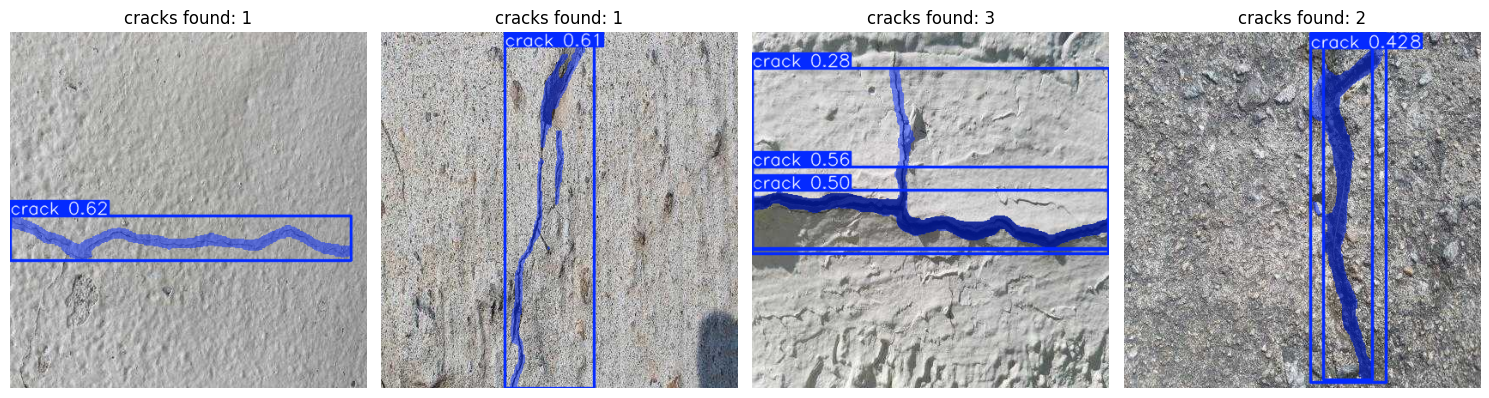

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for panel_axis, image_path in zip(axes, crack_images):
    result = model_seg.predict(image_path, conf=0.25, verbose=False)[0]
    panel_axis.imshow(result.plot()[:, :, ::-1])
    panel_axis.set_title(f'cracks found: {len(result.boxes)}')
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Masks follow the crack inside each box; the fourth image, empty for the detector at `conf=0.25`, now gets two overlapping masks

- **Instance** segmentation → one mask per object, and the count is part of the answer

| Task | One output covers |
|:---|:---|
| Semantic segmentation | every pixel of a class, as a single region |
| Instance segmentation | every pixel of one object, one mask per object |

- For cracks the two are close → a branching crack is one connected shape; the labels decide where an instance ends

---
## Step 7. Why a Mask and Not a Box

- A crack is thin and winding → it covers little of its own box
- `retina_masks=True` → masks at the image size; the sum of a 0/1 mask grid is its pixel count, set against the box area

In [18]:
print('image          mask pixels   box pixels   fill')
for image_path in crack_images:
    result = model_seg.predict(image_path, conf=0.25, retina_masks=True, verbose=False)[0]
    for index in range(len(result.boxes)):
        x1, y1, x2, y2 = result.boxes.xyxy[index]
        box_pixels = float((x2 - x1) * (y2 - y1))
        mask_pixels = float(result.masks.data[index].sum())
        fill = mask_pixels / box_pixels
        print(f'{image_path.name[:12]} {mask_pixels:12.0f} {box_pixels:12.0f}   {fill:.3f}')

image          mask pixels   box pixels   fill
1616.rf.c868         5519        20330   0.271
1675.rf.e3aa         4809        43244   0.111
1686.rf.809f         7487        41774   0.179
1686.rf.809f         7271        28604   0.254
1686.rf.809f         9316        87595   0.106
1706.rf.011d         8673        35628   0.243
1706.rf.011d         7375        23010   0.321


- Fill 0.11–0.32 → most of each box is surface, not crack
- Damage measures such as area or length → read them from the mask

---
## Summary

| Run | Starts from | Box mAP@50, test split |
|:---|:---|:---|
| A: pretrained | COCO weights, no training | 0.011 |
| B: fine-tuned | COCO weights, 20 epochs | 0.531 |
| C: from scratch | random weights, 20 epochs | 0.003 |

- Fine-tuning → teaches the weights a class they could not name before
- Swapping the weights file → the same call trains a segmentation model; a crack fills only part of its box

---
## Exercises

1. `fraction = 0.02`, rerun Step 4 — how much of the score survives on about 74 images instead of 186?
2. `epochs = 5` — all three training calls read that variable; how much of B's 0.53 survives?
3. Predict with `conf=0.05` on the four test images — which extra cracks appear?

In [19]:
# Write your code here